# BIKE-DYNAMICS — Tahap 2: Data Preprocessing & Feature Engineering
**Judul Penelitian:** *Pemodelan dan Simulasi Sistem Dinamik untuk Optimalisasi Ketersediaan Armada Sepeda pada Layanan Bike Sharing Berdasarkan Fluktuasi Permintaan dan Kondisi Cuaca*  
**Platform Pendamping:** `BIKE-DYNAMICS – Dynamic System Simulation for Bike Sharing Management`  
**Mata Kuliah:** Pemodelan dan Simulasi (UTS)  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UTS-MOSI/bike-dynamics/blob/main/notebooks/02_data_preprocessing.ipynb)

---
### Pembersihan Data, Rekayasa Fitur, Pencegahan Data Leakage, & Pembagian Kronologis


In [1]:
# 1. Setup Lingkungan Eksekusi (Google Colab / Lokal)
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Menjalankan di Google Colab. Memasang pustaka pendukung...")
    !pip install -q pandas numpy matplotlib seaborn scikit-learn joblib nbformat
else:
    print("Menjalankan di lingkungan lokal Python.")


Menjalankan di lingkungan lokal Python.


In [2]:
# 2. Konfigurasi Direktori Kerja & Deteksi Path Otomatis
import os
from pathlib import Path

if IN_COLAB:
    # Opsi jika menggunakan Google Drive:
    # from google.colab import drive
    # drive.mount('/content/drive')
    # PROJECT_ROOT = Path('/content/drive/MyDrive/BIKE-DYNAMICS')
    
    colab_default = Path('/content/bike-dynamics')
    colab_alt = Path('/content/BIKE-DYNAMICS-COLAB')
    colab_content = Path('/content')
    
    if (colab_default / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_default
    elif (colab_alt / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_alt
    elif (colab_content / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_content
    elif (colab_content / 'train.csv').exists():
        PROJECT_ROOT = colab_content
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
        import shutil
        if not (PROJECT_ROOT / 'data' / 'raw' / 'train.csv').exists():
            shutil.copy(colab_content / 'train.csv', PROJECT_ROOT / 'data' / 'raw' / 'train.csv')
    else:
        PROJECT_ROOT = colab_default
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
else:
    cwd = Path.cwd()
    if (cwd / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd
    elif (cwd.parent / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd.parent
    else:
        PROJECT_ROOT = cwd

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
PROCESSED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_data.csv'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'

(PROJECT_ROOT / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root  : {PROJECT_ROOT}")
print(f"Raw Data Path : {RAW_DATA_PATH} (Tersedia: {RAW_DATA_PATH.exists()})")


Project Root  : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics
Raw Data Path : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\data\raw\train.csv (Tersedia: True)


## 1. Import Library & Konfigurasi Path

In [3]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 4.5)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

cwd = Path.cwd()
if (cwd / 'data' / 'raw' / 'train.csv').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'data' / 'raw' / 'train.csv').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError('ERROR: File data/raw/train.csv tidak ditemukan!')

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
FIGURES_DIR = ARTIFACTS_DIR / 'preprocessing_figures'

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(RAW_DATA_PATH)
df = df_raw.copy()
print(f'Dataset mentah dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom')

Dataset mentah dimuat: 10,886 baris x 12 kolom


## 2. Konversi `datetime` & Pengurutan Kronologis

In [4]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='raise')
df = df.sort_values('datetime').reset_index(drop=True)

assert df['datetime'].is_monotonic_increasing, 'Urutan waktu tidak monotonik naik!'
assert df['datetime'].duplicated().sum() == 0, 'Terdapat timestamp duplikat!'

print(f'Tipe kolom datetime : {df["datetime"].dtype}')
print(f'Rentang waktu       : {df["datetime"].min()} s.d. {df["datetime"].max()}')

Tipe kolom datetime : datetime64[us]
Rentang waktu       : 2011-01-01 00:00:00 s.d. 2012-12-19 23:00:00


## 3. Ekstraksi Fitur Temporal (Jam, Hari, Bulan, Tahun, Hari Kerja)
Seluruh fitur temporal diekstrak secara deterministik dari stempel waktu saat kejadian ($t$) sehingga tidak mengandung informasi masa depan ($t+k$).

In [5]:
df['hour'] = df['datetime'].dt.hour.astype(int)
df['day'] = df['datetime'].dt.day.astype(int)
df['dayofweek'] = df['datetime'].dt.dayofweek.astype(int)
df['month'] = df['datetime'].dt.month.astype(int)
df['year'] = df['datetime'].dt.year.astype(int)

df['workingday'] = df['workingday'].astype(int)
df['holiday'] = df['holiday'].astype(int)
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

workday_peak = (df['workingday'] == 1) & (df['hour'].isin([7, 8, 9, 17, 18, 19]))
leisure_peak = (df['workingday'] == 0) & (df['hour'].between(11, 16))
df['is_rush_hour'] = (workday_peak | leisure_peak).astype(int)

df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24.0)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12.0)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12.0)

display(df[['datetime', 'year', 'month', 'day', 'hour', 'dayofweek', 'workingday', 'is_weekend', 'is_rush_hour']].head(10))

C:\Users\HS\AppData\Local\Temp\ipykernel_19740\977301697.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dayofweek'] = df['datetime'].dt.dayofweek.astype(int)


,datetime,year,month,day,hour,dayofweek,workingday,is_weekend,is_rush_hour
0,2011-01-01 00:00:00,2011,1,1,0,5,0,1,0
1,2011-01-01 01:00:00,2011,1,1,1,5,0,1,0
2,2011-01-01 02:00:00,2011,1,1,2,5,0,1,0
3,2011-01-01 03:00:00,2011,1,1,3,5,0,1,0
4,2011-01-01 04:00:00,2011,1,1,4,5,0,1,0
5,2011-01-01 05:00:00,2011,1,1,5,5,0,1,0
6,2011-01-01 06:00:00,2011,1,1,6,5,0,1,0
7,2011-01-01 07:00:00,2011,1,1,7,5,0,1,0
8,2011-01-01 08:00:00,2011,1,1,8,5,0,1,0
9,2011-01-01 09:00:00,2011,1,1,9,5,0,1,0


## 4. Pengolahan Variabel Kategorikal (`season` & `weather`)
Memastikan nilai kategori berada pada domain yang valid (`1` sampai `4`). Transformasi *One-Hot Encoding* akan dibungkus di dalam `ColumnTransformer` pada tahap training (Tahap 3) agar parameter encoder hanya di-fit pada data latih.

In [6]:
df['season'] = df['season'].astype(int)
df['weather'] = df['weather'].astype(int)

assert set(df['season'].unique()).issubset({1, 2, 3, 4}), 'Nilai kategori season di luar {1,2,3,4}'
assert set(df['weather'].unique()).issubset({1, 2, 3, 4}), 'Nilai kategori weather di luar {1,2,3,4}'

print('Distribusi kategori season :')
print(df['season'].value_counts().sort_index().to_dict())

print('\nDistribusi kategori weather :')
print(df['weather'].value_counts().sort_index().to_dict())

Distribusi kategori season :
{1: 2686, 2: 2733, 3: 2733, 4: 2734}

Distribusi kategori weather :
{1: 7192, 2: 2834, 3: 859, 4: 1}


## 5. Pemeriksaan Outlier & Penanganan Anomali Sensor Secara Kausal
1. **Deteksi Outlier IQR:** Memeriksa sebaran statistik `temp`, `atemp`, `humidity`, `windspeed`, dan `count`.
2. **Anomali Sensor Kelembapan (`humidity == 0`):** Secara fisik kelembapan udara 0% merupakan kegagalan pembacaan sensor. Untuk menghindari *future leakage*, nilai `0` diimputasi secara **kausal (forward-fill)** dari pembacaan valid jam sebelumnya (`t-1`), bukan menggunakan median seluruh dataset.
3. **Target (`count`):** Nilai tinggi pada jam sibuk merupakan pola operasional nyata (bukan noise), sehingga baris tetap dipertahankan.

,Fitur,Q1,Q3,IQR,Batas_Bawah,Batas_Atas,Jumlah_Outlier_IQR,Persentase (%)
0,temp,13.94,26.24,12.3,-4.51,44.69,0,0.00
1,atemp,16.66,31.06,14.4,-4.93,52.65,0,0.00
2,humidity,47.00,77.00,30.0,2.00,122.00,22,0.20
3,windspeed,7.00,17.00,10.0,-7.99,31.99,227,2.09
4,count,42.00,284.00,242.0,-321.00,647.00,300,2.76


Anomali humidity == 0 sebelum imputasi kausal : 22
Anomali humidity == 0 sesudah imputasi kausal : 0


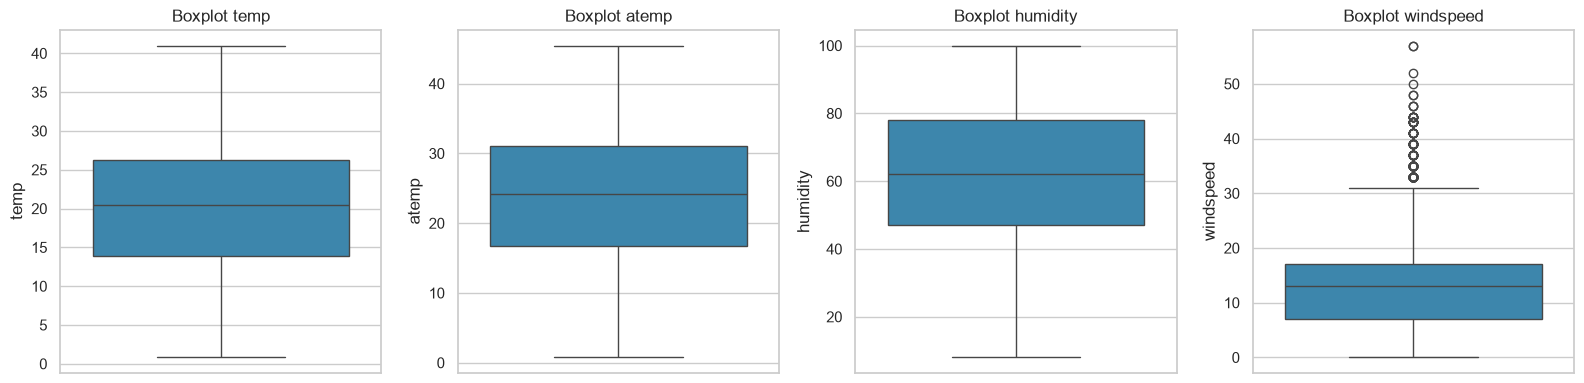

In [7]:
numeric_check_cols = ['temp', 'atemp', 'humidity', 'windspeed', 'count']
iqr_report = []

for col in numeric_check_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = int(((df[col] < lower) | (df[col] > upper)).sum())
    iqr_report.append({
        'Fitur': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Batas_Bawah': round(lower, 2),
        'Batas_Atas': round(upper, 2),
        'Jumlah_Outlier_IQR': n_outliers,
        'Persentase (%)': round(n_outliers / len(df) * 100, 2)
    })

display(pd.DataFrame(iqr_report))

hum_zero_before = int((df['humidity'] == 0).sum())
df['humidity'] = df['humidity'].replace(0, np.nan).ffill().bfill()
hum_zero_after = int((df['humidity'] == 0).sum())

df['is_windspeed_zero'] = (df['windspeed'] == 0).astype(int)

print(f'Anomali humidity == 0 sebelum imputasi kausal : {hum_zero_before}')
print(f'Anomali humidity == 0 sesudah imputasi kausal : {hum_zero_after}')

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for idx, col in enumerate(['temp', 'atemp', 'humidity', 'windspeed']):
    sns.boxplot(y=df[col], ax=axes[idx], color='#2b8cbe')
    axes[idx].set_title(f'Boxplot {col}')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_numeric_boxplots.png', dpi=150)
plt.show()

## 6. Pencegahan Data Leakage & Penetapan Fitur Input vs Target
- **Kolom Dibuang (Anti-Leakage):** `casual` dan `registered` dibuang karena keduanya merupakan komponen penyusun langsung variabel target (`count = casual + registered`) dan tidak tersedia saat melakukan prediksi permintaan baru.
- **Kolom Referensi Waktu:** `datetime` dipertahankan pada file hasil preprocessing untuk kebutuhan *chronological train-test split* di Tahap 3, namun tidak dimasukkan sebagai fitur numerik mentah ke model.
- **Target Prediksi:** `count`.

In [8]:
LEAKAGE_COLUMNS = ['casual', 'registered']
REFERENCE_COLUMNS = ['datetime']
TARGET_COLUMN = 'count'

CATEGORICAL_FEATURES = ['season', 'weather']
NUMERICAL_FEATURES = [
    'year', 'month', 'day', 'hour', 'dayofweek',
    'holiday', 'workingday', 'is_weekend', 'is_rush_hour',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'temp', 'atemp', 'humidity', 'windspeed', 'is_windspeed_zero'
]
FEATURE_COLUMNS = CATEGORICAL_FEATURES + NUMERICAL_FEATURES

overlap_leakage = set(FEATURE_COLUMNS).intersection(set(LEAKAGE_COLUMNS + [TARGET_COLUMN]))
assert len(overlap_leakage) == 0, f'Terdeteksi data leakage pada fitur: {overlap_leakage}'

selected_columns = REFERENCE_COLUMNS + FEATURE_COLUMNS + [TARGET_COLUMN]
df_cleaned = df[selected_columns].copy()

print(f'Jumlah fitur input terpilih : {len(FEATURE_COLUMNS)}')
print(f'Fitur Kategorikal ({len(CATEGORICAL_FEATURES)})     : {CATEGORICAL_FEATURES}')
print(f'Fitur Numerik/Biner ({len(NUMERICAL_FEATURES)})  : {NUMERICAL_FEATURES}')
print(f'Variabel Target             : {TARGET_COLUMN}')
print(f'Kolom Leakage Dibuang       : {LEAKAGE_COLUMNS}')

Jumlah fitur input terpilih : 20
Fitur Kategorikal (2)     : ['season', 'weather']
Fitur Numerik/Biner (18)  : ['year', 'month', 'day', 'hour', 'dayofweek', 'holiday', 'workingday', 'is_weekend', 'is_rush_hour', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'temp', 'atemp', 'humidity', 'windspeed', 'is_windspeed_zero']
Variabel Target             : count
Kolom Leakage Dibuang       : ['casual', 'registered']


## 7. Validasi Akhir & Penyimpanan `data/processed/cleaned_data.csv`

In [9]:
assert df_cleaned.isnull().sum().sum() == 0, 'Masih terdapat missing values pada df_cleaned!'
assert len(df_cleaned) == len(df_raw), 'Jumlah baris berubah dari dataset asli!'

CLEANED_DATA_PATH = PROCESSED_DIR / 'cleaned_data.csv'
df_cleaned.to_csv(CLEANED_DATA_PATH, index=False)

preprocessing_summary = {
    'source_dataset': str(RAW_DATA_PATH.relative_to(PROJECT_ROOT)),
    'output_dataset': str(CLEANED_DATA_PATH.relative_to(PROJECT_ROOT)),
    'num_rows': int(df_cleaned.shape[0]),
    'num_columns': int(df_cleaned.shape[1]),
    'categorical_features': CATEGORICAL_FEATURES,
    'numerical_features': NUMERICAL_FEATURES,
    'all_feature_columns': FEATURE_COLUMNS,
    'target_column': TARGET_COLUMN,
    'dropped_leakage_columns': LEAKAGE_COLUMNS,
    'sensor_fixes': {
        'humidity_zero_imputed_causal': hum_zero_before
    }
}

summary_path = ARTIFACTS_DIR / 'preprocessing_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(preprocessing_summary, f, indent=2)

print(f'Dataset bersih berhasil disimpan ke : {CLEANED_DATA_PATH}')
print(f'Metadata preprocessing tersimpan di : {summary_path}')
display(df_cleaned.head())

Dataset bersih berhasil disimpan ke : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\data\processed\cleaned_data.csv
Metadata preprocessing tersimpan di : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\preprocessing_summary.json


,datetime,season,weather,year,month,day,hour,dayofweek,holiday,workingday,is_weekend,is_rush_hour,hour_sin,hour_cos,month_sin,month_cos,temp,atemp,humidity,windspeed,is_windspeed_zero,count
0,2011-01-01 00:00:00,1,1,2011,1,1,0,5,0,0,1,0,0.000000,1.000000,0.5,0.866025,9.84,14.395,81.0,0.0,1,16
1,2011-01-01 01:00:00,1,1,2011,1,1,1,5,0,0,1,0,0.258819,0.965926,0.5,0.866025,9.02,13.635,80.0,0.0,1,40
2,2011-01-01 02:00:00,1,1,2011,1,1,2,5,0,0,1,0,0.500000,0.866025,0.5,0.866025,9.02,13.635,80.0,0.0,1,32
3,2011-01-01 03:00:00,1,1,2011,1,1,3,5,0,0,1,0,0.707107,0.707107,0.5,0.866025,9.84,14.395,75.0,0.0,1,13
4,2011-01-01 04:00:00,1,1,2011,1,1,4,5,0,0,1,0,0.866025,0.500000,0.5,0.866025,9.84,14.395,75.0,0.0,1,1


## 8. Kesimpulan Tahap Preprocessing
1. Seluruh baris data (100% tanpa penghapusan sampel) telah diurutkan secara kronologis berdasarkan `datetime`.
2. Sebanyak **20 fitur input** (2 fitur kategorikal dan 18 fitur numerik/temporal/siklikal) telah disiapkan tanpa menyertakan kolom `casual` dan `registered` sehingga bebas dari *target leakage*.
3. Anomali pembacaan sensor kelembapan (`humidity == 0`) telah diperbaiki secara kausal (*forward-fill*) tanpa membocorkan informasi masa depan.
4. Dataset siap digunakan untuk proses pelatihan model dengan skema *chronological train-test split* pada **Tahap 3 (`03_train_demand_model.ipynb`)**.